## Finding 3

* Restaurants that failed their first inspection were marked permanently closed 16.4% of the time, compared with 15.7% of those that passed, making the gap between them too small to treat inspection results as a strong reason for closure and put focus on the Google reviews that show that restaurants with a number of reviews above the median are less likely to be marked permanently closed regardless of the inspection pass/fail results.

The inspection results can be Pass, Pass w/ Conditions and Fail. We will only focus on pass and fail:

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
plot3 = pd.read_csv("../EDA_Checkpoint/data/plot3.csv") 
print(len(plot3)) 
plot3.groupby("results")["permanently_closed"].agg(["mean", "size"])

3251


,mean,size
results,,
Fail,0.163953,860
Pass,0.156780,944
Pass w/ Conditions,0.121631,1447


In [2]:
restaurant_pass = plot3.loc[plot3["results"] == "Pass"]
pass_rate = restaurant_pass["permanently_closed"].mean()
print("Number of restaurants that passed the inspection:", len(restaurant_pass))
print("Pass closure rate", round(pass_rate*100, 1), "%")

Number of restaurants that passed the inspection: 944
Pass closure rate 15.7 %


In [3]:
restaurant_fail = plot3.loc[plot3["results"] == "Fail"]
fail_rate = restaurant_fail["permanently_closed"].mean()
print("Number of restaurants that failed the inspection:", len(restaurant_fail))
print("Fail closure rate", round(fail_rate*100, 1), "%")

Number of restaurants that failed the inspection: 860
Fail closure rate 16.4 %


In [4]:
gap = fail_rate - pass_rate
print("Gap:", round(gap*100, 1))

Gap: 0.7


### 95% confidence interval

In [5]:
standar_error = np.sqrt(fail_rate * (1-fail_rate)/len(restaurant_fail) + pass_rate*(1-pass_rate)/len(restaurant_pass))
confidence_interval_lower_range = gap - 1.96 * standar_error
confidence_interval_higher_range = gap + 1.96 * standar_error
print("95% confidence interval: ", round(confidence_interval_lower_range*100, 1), "-", round(confidence_interval_higher_range*100, 1))

95% confidence interval:  -2.7 - 4.1


In the sample of 3251 restaurants with know open/permanently closed status we were looking at, 16.4% of those who failed the inspection were marked permanently closed and 15.7% passed, creating a gap of 0.7 percentage points. However, in our calculation of the 95% confidence interval, we found that the confidence interval for this gap between restaurants that failed and passed inspections that were permanently closed ranges from -2.7 to 4.1 percentage points. This means that we can't confidently conclude that restaurants that fail or pass the inspection are more likely to be permanently closed, and therefore the inspection results are not clearly associated with whether the retsaurants will be marked permanently closed

## Logistic Model

* In this step, we will use the Logistic Model to compare restaurants with the same number of reviews that failed and passed their first inspection. Since greater number of reviews lead to lower closure rates, we will inspect if our finding with 95% confidence interval where we concluded that fail/pass inspection don't have a great impact on whether the restaurant will close in the future still holds when the number of reviews for pass and fail are same.

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
plot3 = pd.read_csv("../EDA_Checkpoint/data/plot3.csv")

In [8]:
from sklearn.linear_model import LogisticRegression 

plot3["failed"] = (plot3["results"] == "Fail").astype(int) 
plot3["pass_conditions"] = (plot3["results"] == "Pass w/ Conditions").astype(int) 
plot3["log_reviews"] = np.log(plot3["num_of_reviews"] + 1) 
X = plot3[["failed", "pass_conditions", "log_reviews"]] 
y = plot3["permanently_closed"]
lr_check = LogisticRegression(C=np.inf).fit(X, y) 
print("Fail odds ratio:", round(np.exp(lr_check.coef_[0][0]), 2)) 

Fail odds ratio: 1.1


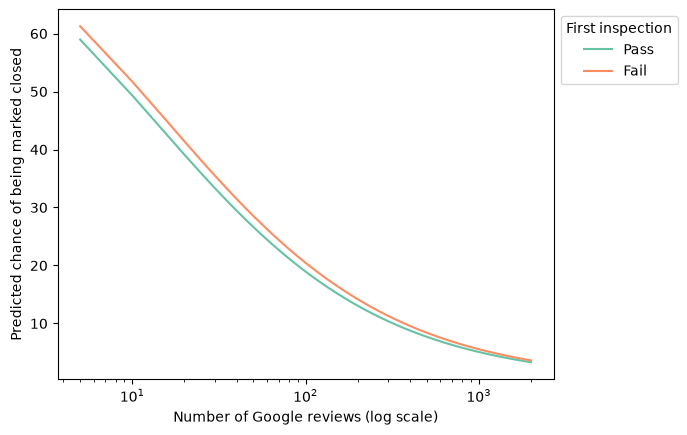

In [9]:
reviews = np.arange(5, 2001, 5)

df_pass = pd.DataFrame({"failed": 0, "pass_conditions": 0, "log_reviews": np.log(reviews + 1)})
df_pass["result"] = "Pass"
df_fail = pd.DataFrame({"failed": 1, "pass_conditions": 0, "log_reviews": np.log(reviews + 1)})
df_fail["result"] = "Fail"

df_new = pd.concat([df_pass, df_fail])
df_new["num_of_reviews"] = list(reviews) * 2
df_new["chance_closed"] = lr_check.predict_proba(df_new[X.columns])[:, 1] * 100

result = ["Pass", "Fail"]
ax = sns.lineplot(df_new, x = "num_of_reviews", y = "chance_closed", hue = "result", palette = "Set2", hue_order = result)
ax.set_xscale("log")
ax.set_xlabel("Number of Google reviews (log scale)")
ax.set_ylabel("Predicted chance of being marked closed")
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1), title = "First inspection")
plt.show()

* The graph shows the relationship we expected. Two lines are model's predicted chance of closure based on whether the restaurant failed or passed their first inspection. These lines are very close to each other and the orange line shows that restaurants that fail their first inspection have a slightly higher odds of being marked closed (1.1). As number of google reviews increases, predicted chance of being marked closed decreaseses and both lines follow the downward slope.

In [10]:
fail_coef = lr_check.coef_[0][0]

np.random.seed(1)
fail_coefs = []

for i in range(1000):
    sample = plot3.sample(len(plot3), replace = True)
    model = LogisticRegression(C = np.inf).fit(sample[X.columns], sample["permanently_closed"])
    fail_coefs.append(model.coef_[0][0]) 
    
standar_error = np.std(fail_coefs)
confidence_interval_lower_range = fail_coef - 1.96 * standar_error
confidence_interval_higher_range = fail_coef + 1.96 * standar_error
print("Fail odds ratio:", round(np.exp(fail_coef), 2))
print("95% confidence interval:", round(np.exp(confidence_interval_lower_range), 2), "-", round(np.exp(confidence_interval_higher_range), 2))

Fail odds ratio: 1.1
95% confidence interval: 0.85 - 1.42


* In our calculation of the 95% confidence interval, we found that the odds ratio ranges from 0.85 to 1.42. Since the range can be below 1, above 1 or 1, we can't confidently conclude that failing the first inspection increases, decreases or is linked at all to odds of closing the restaurant, meaning we can't conclude that failing an inspection is linked to the closure of the restaurant.

### Pass w/condition check

* Out of 3251 restaurants with known open/permanently closed status, 1447 of them had the result Pass w/Condition. Without considering this group we have our finding that restaurants that failed their first inspection were marked permanently closed 16.4% of the time, compared with 15.7% of those that passed, but we want to check if counting this group as either pass or fail would change our finding and make the gap more significant.

In [11]:
plot3["log_reviews"] = np.log(plot3["num_of_reviews"] + 1)

cases = {
    "1) Leave out Pass w/Condition":     plot3.loc[plot3["results"] != "Pass w/ Conditions"].copy(),
    "2) Count Pass w/Condition as Pass": plot3.replace({"results": {"Pass w/ Conditions": "Pass"}}),
    "3) Count Pass w/Condition as Fail": plot3.replace({"results": {"Pass w/ Conditions": "Fail"}}),
}

for name, df in cases.items():
    restaurant_pass = df.loc[df["results"] == "Pass"]
    restaurant_fail = df.loc[df["results"] == "Fail"]
    pass_rate = restaurant_pass["permanently_closed"].mean()
    fail_rate = restaurant_fail["permanently_closed"].mean()
    gap = fail_rate - pass_rate
    standar_error = np.sqrt(fail_rate * (1-fail_rate)/len(restaurant_fail) + pass_rate*(1-pass_rate)/len(restaurant_pass))

    df["failed"] = (df["results"] == "Fail").astype(int)
    lr = LogisticRegression(C=np.inf).fit(df[["failed", "log_reviews"]], df["permanently_closed"])

    print(name)
    print("- Fail:", round(fail_rate*100, 1), "% closed (n =", len(restaurant_fail), ")")
    print("- Pass:", round(pass_rate*100, 1), "% closed (n =", len(restaurant_pass), ")")
    print("- Gap:", round(gap*100, 1), " 95% CI:", round((gap - 1.96*standar_error)*100, 2), "-", round((gap + 1.96*standar_error)*100, 2))
    print("- Fail odds ratio (adjusted for reviews):", round(np.exp(lr.coef_[0][0]), 2))

1) Leave out Pass w/Condition
- Fail: 16.4 % closed (n = 860 )
- Pass: 15.7 % closed (n = 944 )
- Gap: 0.7  95% CI: -2.67 - 4.11
- Fail odds ratio (adjusted for reviews): 1.1
2) Count Pass w/Condition as Pass
- Fail: 16.4 % closed (n = 860 )
- Pass: 13.6 % closed (n = 2391 )
- Gap: 2.8  95% CI: 0.02 - 5.67
- Fail odds ratio (adjusted for reviews): 1.31
3) Count Pass w/Condition as Fail
- Fail: 13.7 % closed (n = 2307 )
- Pass: 15.7 % closed (n = 944 )
- Gap: -1.9  95% CI: -4.65 - 0.77
- Fail odds ratio (adjusted for reviews): 0.87


* Looking at case 2, where we count Pass w/Condition as Pass, we can see that the gap between the percentage of restaurants that Pass and Fail got bigger (2.8). In this case, restaurants that failed their first inspection still have a greater percentage of closures than those who passed, same as in case 1.
* We can see that the confidence interval changed and is going from 0.02 to 5.67. CI is very close to 0, it's worth noting that this interval is at the boundary, but we didn't count this as enough sufficient reason to disagree with our finding. Additionally looking at the odds ratio, we can see that it is not too different from the failed odds ratio for our original case (1.1 vs 1.31). 
* Looking at case 3, where we count Pass w/Condition as Fail, we can see that the gap between the percentage of restaurants that Pass and Fail got smaller (-1.9) because, in this case, restaurants that failed their first inspection have a lower percentage of closure than those who pass.
* We can see that the confidence interval changed and is going from -4.65 to 0.77. Considering that 0 is still included in our confidence interval, inspection results are not clearly associated with whether the restaurants will be marked permanently closed, like in our original finding. Looking at the odds ratio, we can see that it is not too different from the fail odds ratio for our original case (1.1 vs 0.87)


## Results from 2018-2019 and 2020-2021

* We want to check whether the inspection results from 2018-2019 and from 2020 to 2021 might have an impact on our finding. 2018-2019 were the years where restaurants were operating regularly and in a normal way, therefore this time is important for looking at the relationship of inspection results and the impact they had on closing the retsaurants. In 2020-2021, many restaurants got closed because of the COVID because of different things such as lack of customers, no profit, safety reasons etc. not inspection reasons.

In [12]:
plot3["inspection_date"] = pd.to_datetime(plot3["inspection_date"])
plot3["year"] = plot3["inspection_date"].dt.year

base = plot3.loc[plot3["results"] != "Pass w/ Conditions"]
periods = {
    "2018-2019": base.loc[base["year"] <= 2019].copy(),
    "2020-2021": base.loc[base["year"] >= 2020].copy(),
}

for name, df in periods.items():
    restaurant_pass = df.loc[df["results"] == "Pass"]
    restaurant_fail = df.loc[df["results"] == "Fail"]
    pass_rate = restaurant_pass["permanently_closed"].mean()
    fail_rate = restaurant_fail["permanently_closed"].mean()
    gap = fail_rate - pass_rate
    standar_error = np.sqrt(fail_rate * (1-fail_rate)/len(restaurant_fail) + pass_rate*(1-pass_rate)/len(restaurant_pass))

    df["failed"] = (df["results"] == "Fail").astype(int)
    lr_check = LogisticRegression(C=np.inf).fit(df[["failed", "log_reviews"]], df["permanently_closed"])

    print(name)
    print("- Fail:", round(fail_rate*100, 1), "% closed (n =", len(restaurant_fail), ")")
    print("- Pass:", round(pass_rate*100, 1), "% closed (n =", len(restaurant_pass), ")")
    print("- Gap:", round(gap*100, 1), " 95% CI:", round((gap - 1.96*standar_error)*100, 2), "-", round((gap + 1.96*standar_error)*100, 2))
    print("- Fail odds ratio (adjusted for reviews):", round(np.exp(lr_check.coef_[0][0]), 2))

2018-2019
- Fail: 18.3 % closed (n = 727 )
- Pass: 17.9 % closed (n = 792 )
- Gap: 0.4  95% CI: -3.51 - 4.24
- Fail odds ratio (adjusted for reviews): 1.05
2020-2021
- Fail: 6.0 % closed (n = 133 )
- Pass: 3.9 % closed (n = 152 )
- Gap: 2.1  95% CI: -3.02 - 7.16
- Fail odds ratio (adjusted for reviews): 1.65


* Looking at the results we got for 2018-2019 we can clearly see that the gap doesn't hide any patterns, since this is the time where retsuarants opereted normally and we would be able to clearly see the difference between pass and fail if the inspection did have a significant impact on later closure of the restaurants. Most of our data came from this time and we can see the small percentage difference between restaurants that closed after failed/pass their first inspection and the gap is 0.4. The confidence interval goes from -3.51 to 4.24 so it is also consistent with our previous findings, meaning inspection results are not clearly associated with whether the restaurants will be marked permanently closed.
* Looking at results from the COVID period we can see that 6% of restaurants that failed the first inspection were marked closed and 3.9% that passed. The greater gap in this time might be explained by the fact that we are looking at the smaller sample of restaurants. Confidence interval lies between -3.02 - 7.16 and this time period is also consistent with our previous findings.
* We can safely conclude that neither 2018-2019 nor 2020-2021 show a difference from our finding, in other words, there is no clear link between the inspection results and whether the restaurant will be closed.

### Missing status

* In our EDA we excluded records marked 'temorarily closed' and records with missing status. Out of 8,034 unique Chicago restaurants, 2,313 of them were missing status and were excluded from our analasys. These drops should not have an impact on our finding unless the ratio between the dropped restaurants that failed their first inspection and those who passed is high. To check our finding we will look at our data without dropping 'missing status':

In [13]:
plot3 = pd.read_csv("../EDA_Checkpoint/data/plot3.csv")

linked = pd.read_csv("../EDA_Checkpoint/data/linked.csv")
linked = linked.loc[linked["results"] != "Pass w/ Conditions"]

linked["missing_status"] = (~linked["gmap_id"].isin(plot3["gmap_id"])).astype(int)

print(linked.groupby("results")["missing_status"].agg(["mean", "size"]))

restaurant_pass = linked.loc[linked["results"] == "Pass"]
restaurant_fail = linked.loc[linked["results"] == "Fail"]
pass_rate = restaurant_pass["missing_status"].mean()
fail_rate = restaurant_fail["missing_status"].mean()
gap = fail_rate - pass_rate
standar_error = np.sqrt(fail_rate * (1-fail_rate)/len(restaurant_fail) + pass_rate*(1-pass_rate)/len(restaurant_pass))
print("Missing-status gap:", round(gap*100, 1), " 95% CI:", round((gap - 1.96*standar_error)*100, 2), "-", round((gap + 1.96*standar_error)*100, 2))

             mean  size
results                
Fail     0.309791  1246
Pass     0.363023  1482
Missing-status gap: -5.3  95% CI: -8.87 - -1.78


* We can see that around 30% of restaurants that failed their first inspection were removed and around 36% of those that passed, which is slightly more. The gap is -5.3 and CI ranges from -8.87 to -1.78, which doesn't include 0. Looking at this we can conclude that there was more restaurants that passed that were excluded from the analasys. We marked this as a limitation and don't think that this changes our finding because of the small difference in percentage and the previous results we got from different checks.